# ToolIA-Bot — Datos y embeddings con CRISP-ML(Q)

Este estudio examina la preparación de un corpus institucional de la Universidad Tecnológica de Bolívar (UTB) y su representación mediante embeddings. El propósito es determinar en qué medida la búsqueda semántica permite localizar información pertinente frente a una alternativa basada en TF-IDF ( Term Frequency – Inverse Document Frequency o Frecuencia de Término – Frecuencia Inversa de Documento), considerando también el tiempo de consulta y el consumo computacional.

El análisis comprende los documentos descargados, la calidad del texto extraído, la fragmentación, la construcción de un índice vectorial y la evaluación de la recuperación.

| Fase | Secciones | Evidencia |
|---|---|---|
| Negocio y datos | 1 | Problema, PEAS y criterios |
| Preparación | 2 | Inventario, calidad y fragmentación |
| Modelado | 3 | TF-IDF frente a embeddings |
| Evaluación | 4–5 | Recuperación, incertidumbre, errores y consumo |
| Exportación/integración | 6–7 | Índice persistente y contrato de consulta |
| Monitoreo | 8 | Actualización sobre copia sintética |

La extracción se apoya en `scripts/extract_text.py` y la representación vectorial en `src/embeddings.py`. Esta separación permite estudiar los resultados en el notebook y reutilizar posteriormente el componente de recuperación. Los textos, las dependencias y los resultados persistidos corresponden a la versión del corpus descrita en las secciones siguientes.

## 0. Configuración
La comparación utiliza una semilla fija y recupera cinco fragmentos por consulta. Los parámetros se registran junto con las versiones de las dependencias y las huellas del corpus, de manera que cada resultado pueda asociarse con su configuración de origen. El tamaño de las ventanas y el solape se expresan en caracteres.

La ejecución distingue entre extracción, construcción del índice y análisis de consultas, mientras que las opciones de regeneración permiten repetir una etapa de forma explícita, en las ejecuciones posteriores se reutilizan el índice y los resultados compatibles con la configuración registrada.


In [1]:
import sys, os, json, re, time, tempfile, logging, threading, unicodedata
from pathlib import Path
from datetime import datetime, timezone
from contextlib import contextmanager
import importlib.metadata as metadata

ROOT = Path.cwd().resolve()
while not (ROOT / 'data/preguntas.csv').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'src/embeddings.py').exists(), 'Abrir desde el repositorio ToolIA-Bot'
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from embeddings import (cargar_documentos, fragmentar_documentos, construir_indice,
                        cargar_indice, generar_embeddings, validar_vectores,
                        identidad_modelo, guardar_json, huella, MODELO, RUTA_INDICE)

SEED = 42
np.random.seed(SEED)
K = 5
OBJETIVO_RECALL = 0.80
FRAGMENTACION = {'max_caracteres': 1600, 'solape': 180}
REEXTRAER = False
RECONSTRUIR = False
RECALCULAR_CONSULTAS = False
REPETICIONES_TIEMPO = 3
SALIDA = ROOT / 'experiments/crisp_datos'
SALIDA.mkdir(parents=True, exist_ok=True)
CACHE_ANTERIOR = Path(os.environ.get('LOCALAPPDATA', '.')) / 'ToolIA-Bot/chroma/embeddings.sqlite3'
pd.set_option('display.max_colwidth', 120)
plt.rcParams['figure.dpi'] = 110
ROJO, GRIS = '#C10230', '#6F7271'
print('Raíz del repositorio:', ROOT)
print('Ubicación del índice persistente:', RUTA_INDICE)
display(pd.DataFrame({'paquete': ['numpy','pandas','chromadb','scikit-learn','codecarbon'],
                      'version': [metadata.version(p) for p in ['numpy','pandas','chromadb','scikit-learn','codecarbon']]}))

Raíz del repositorio: C:\Users\mjuli\OneDrive\Documentos\GitHub\ToolIA-Bot
Ubicación del índice persistente: C:\Users\mjuli\AppData\Local\ToolIA-Bot\crisp_vectorial


,paquete,version
0,numpy,2.5.4
1,pandas,3.1.1
2,chromadb,1.5.9
3,scikit-learn,1.9.1
4,codecarbon,3.3.2


### Medición por etapa
Las mediciones abarcan la máquina completa porque la generación de embeddings se ejecuta en Ollama, en un proceso separado del notebook. En el registro de construcción, la energía de CPU se obtuvo mediante Windows EMI y la de GPU mediante NVML, el consumo de RAM se estimó con el modelo de CodeCarbon. También se registraron la duración, la utilización de CPU y la memoria utilizada por el conjunto del equipo.

Las emisiones se estimaron con el factor eléctrico nacional de Colombia. El alcance corresponde a la operación de CPU, GPU y RAM, sin incluir fabricación del equipo, pantalla ni tráfico de red. Las etapas de pocos segundos se interpretan como mediciones indicativas, ya que su duración limita la resolución de la estimación.

In [2]:
recursos = json.loads((SALIDA / 'recursos_etapas.json').read_text(encoding='utf-8')) if (SALIDA / 'recursos_etapas.json').exists() else []

@contextmanager
def medir(etapa):
    import psutil
    from codecarbon import OfflineEmissionsTracker
    muestras, stop = [], threading.Event()
    def muestrear():
        while not stop.is_set():
            muestras.append((psutil.cpu_percent(), psutil.virtual_memory().used / 2**30))
            stop.wait(1)
    hilo = threading.Thread(target=muestrear, daemon=True)
    hilo.start()
    tracker, advertencia = None, ''
    try:
        tracker = OfflineEmissionsTracker(country_iso_code='COL', tracking_mode='machine',
            measure_power_secs=5, pue=1.0, project_name='ToolIA_CRISP_' + etapa,
            output_dir=str(SALIDA), output_file=etapa + '_emissions.csv',
            save_to_api=False, log_level='warning')
        tracker.start()
    except Exception as exc:
        advertencia, tracker = str(exc), None
    inicio = time.perf_counter()
    completada = False
    try:
        yield
        completada = True
    finally:
        emisiones, datos = None, None
        if tracker is not None:
            try:
                emisiones = tracker.stop()
                datos = tracker.final_emissions_data
            except Exception as exc:
                advertencia += str(exc)
        stop.set()
        hilo.join(timeout=3)
        duracion = time.perf_counter() - inicio
        registro = {'etapa': etapa, 'duracion_s': duracion,
            'energy_kwh': getattr(datos, 'energy_consumed', None),
            'emissions_g_co2e': None if emisiones is None else emisiones * 1000,
            'ram_peak_gib': max((m[1] for m in muestras), default=None),
            'cpu_mean_percent': np.mean([m[0] for m in muestras]).item() if muestras else None,
            'country': 'COL', 'tracking_mode': 'machine', 'terminado': completada,
            'advertencia': advertencia, 'fecha_utc': datetime.now(timezone.utc).isoformat(),
            'nota': 'Duración corta: estimación indicativa' if duracion < 15 else 'Incluye todas las cargas de la máquina'}
        recursos.append(registro)
        guardar_json(SALIDA / 'recursos_etapas.json', recursos)

## 1. Fase 1 — Entendimiento del negocio
### Problema y tarea
La información institucional se encuentra distribuida entre páginas web, reglamentos, resoluciones y otros documentos. Una consulta sobre matrícula o becas puede requerir localizar una disposición concreta y distinguirla de otras que emplean términos semejantes. Las cifras, la modalidad del programa y las condiciones de aplicación forman parte de la respuesta, por lo que recuperar un texto relacionado con el tema resulta insuficiente cuando omite alguno de esos elementos.

El componente estudiado recibe una pregunta y devuelve fragmentos ordenados con su procedencia. Su utilidad para estudiantes, aspirantes y personal de la institución depende de que esos fragmentos contengan información pertinente y puedan contrastarse con la fuente original. La pregunta que orienta este estudio es: ¿la representación mediante embeddings mejora la recuperación de evidencia institucional frente a TF-IDF y qué recursos adicionales requiere?

La formulación PEAS vincula esta tarea con cuatro elementos. El desempeño se mide mediante la recuperación en los cinco primeros resultados, la estabilidad y el costo de consulta. El entorno comprende el corpus institucional y sus versiones. Los sensores corresponden a preguntas, textos, metadatos y hashes. Los actuadores producen resultados recuperados y actualizan el índice. Cada consulta constituye un episodio independiente, mientras que el mantenimiento es secuencial y depende de cambios en fuentes parcialmente observables.

### Técnica y alternativas
TF-IDF ofrece una referencia sencilla y explicable, esta representa la importancia de palabras y combinaciones de palabras dentro del corpus. Los embeddings incorporan relaciones semánticas que pueden favorecer consultas con vocabulario diferente al de los documentos. Esa flexibilidad introduce un costo adicional de inferencia y también la posibilidad de recuperar pasajes temáticamente cercanos que no contienen el dato solicitado.

Se empleó EmbeddingGemma 300M multilingüe, sin ajuste de pesos, y Chroma para almacenar vectores y metadatos. El uso de conocimiento documental externo es consistente con el enfoque de recuperación descrito por Lewis et al. (2020). Este estudio se concentra en la selección de evidencia; la calidad de las respuestas generadas constituye una evaluación posterior, basada en completitud, respaldo documental y alucinación.

In [3]:
criterios = pd.DataFrame([
    ['Índice íntegro', '1 vector finito y no nulo por fragmento; metadatos trazables'],
    ['Recuperación principal', 'Recall@5 >= 80% solo con relevancias verificadas'],
    ['Comparación', 'TF-IDF vs. embeddings sobre los mismos fragmentos/preguntas'],
    ['Proxies automáticos', 'Hit de fuente y cobertura de artículos, NO fidelidad'],
    ['Persistencia', 'Recargar sin volver a generar los vectores documentales'],
    ['Costo', 'Tiempo, RAM, kWh y gCO2e; distinguir caché y limitaciones'],
    ['Prueba histórica', '57 preguntas: 47 respondibles y 10 negativas declaradas']
], columns=['criterio', 'condición'])
display(criterios)

,criterio,condición
0,Índice íntegro,1 vector finito y no nulo por fragmento; metadatos trazables
1,Recuperación principal,Recall@5 >= 80% solo con relevancias verificadas
2,Comparación,TF-IDF vs. embeddings sobre los mismos fragmentos/preguntas
3,Proxies automáticos,"Hit de fuente y cobertura de artículos, NO fidelidad"
4,Persistencia,Recargar sin volver a generar los vectores documentales
5,Costo,"Tiempo, RAM, kWh y gCO2e; distinguir caché y limitaciones"
6,Prueba histórica,57 preguntas: 47 respondibles y 10 negativas declaradas


## 2. Fase 2 — Preparación y validación de datos
El inventario inicial comprende 699 archivos: 410 páginas HTML, 276 PDF y 13 documentos en formatos Word y Excel. Aunque las páginas web son más numerosas, los PDF representan la mayor parte del volumen descargado, con aproximadamente 833 MiB. Esta diferencia anticipa necesidades de procesamiento distintas: una página breve y un reglamento extenso no aportan la misma cantidad de texto ni requieren la misma revisión.

El índice se construye a partir de documentos institucionales, manteniendo las preguntas y sus respuestas de referencia separadas del corpus. Esta distinción evita que la búsqueda recupere directamente las soluciones del conjunto de evaluación. Los originales se conservan y cada texto procesado se vincula con su archivo y fuente. Los documentos fiscales potencialmente identificables y los currículums se apartan preventivamente del procesamiento.

,archivos,mib
formato,,
.doc,1,0.07
.docx,9,1.20
.html,410,233.54
.pdf,276,832.83
.xlsx,3,0.14


,,preguntas
categoria,tiene_respuesta,
admisiones,si,5
asistencia,si,2
becas_financiacion,si,17
calificaciones,si,2
distinciones,si,4
estados_academicos,si,6
general,si,1
ingles,si,1
matricula,si,7


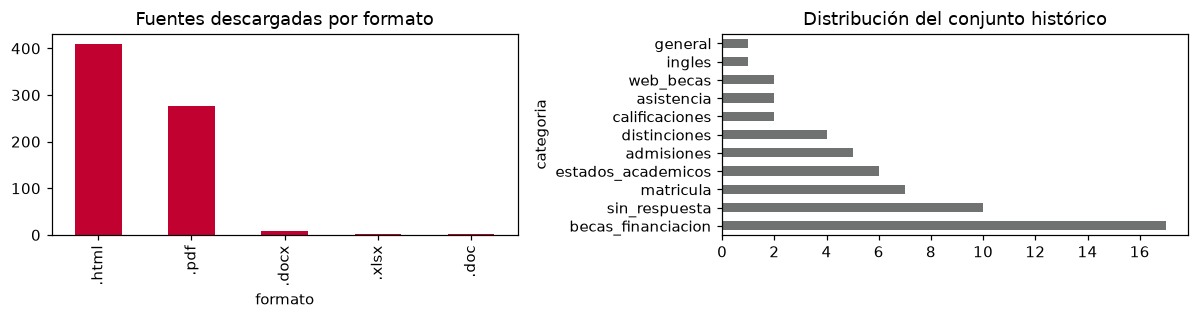

In [4]:
archivos = [p for p in (ROOT / 'data/raw').rglob('*') if p.is_file()]
assert archivos, 'Faltan descargas institucionales en data/raw'
inventario = pd.DataFrame([{'archivo': p.relative_to(ROOT / 'data').as_posix(),
    'formato': p.suffix.lower(), 'mib': p.stat().st_size / 2**20} for p in archivos])
preguntas = pd.read_csv(ROOT / 'data/preguntas.csv', dtype={'id': str}, encoding='utf-8-sig', keep_default_na=False)
assert preguntas['id'].is_unique and len(preguntas) == 57
assert preguntas['tiene_respuesta'].value_counts().to_dict() == {'si': 47, 'no': 10}
display(inventario.groupby('formato').agg(archivos=('archivo','size'), mib=('mib','sum')).round(2))
display(preguntas.groupby(['categoria','tiene_respuesta']).size().rename('preguntas').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
inventario['formato'].value_counts().plot.bar(ax=axes[0], color=ROJO, title='Fuentes descargadas por formato')
preguntas['categoria'].value_counts().plot.barh(ax=axes[1], color=GRIS, title='Distribución del conjunto histórico')
plt.tight_layout(); plt.show()

In [5]:
# La extracción se repite únicamente cuando REEXTRAER está activado.
if REEXTRAER:
    import subprocess
    with medir('extraccion'):
        subprocess.run([sys.executable, str(ROOT / 'scripts/extract_text.py')], cwd=ROOT, check=True)

documentos, auditoria_carga = cargar_documentos()
datos = pd.DataFrame([{'document_id': d['document_id'], 'archivo': d['archivo_origen'],
    'formato': d['tipo'], 'url': d['fuente_url'], 'titulo': d['titulo'],
    'paginas': len(d['paginas']), 'caracteres': sum(len(p['texto']) for p in d['paginas']),
    'paginas_vacias': sum(not p['texto'].strip() for p in d['paginas']),
    'paginas_pendientes_ocr': sum(bool(p.get('needs_ocr')) for p in d['paginas']),
    'version_extractor': d.get('extractor_version', 'sin versión')} for d in documentos])
catalogo_path = ROOT / 'data/processed/catalog.json'
catalogo = json.loads(catalogo_path.read_text(encoding='utf-8')) if catalogo_path.exists() else {}
pendientes = pd.DataFrame([r for r in catalogo.get('files', []) if r.get('estado') in ['pendiente','cuarentena']])
display(datos[['caracteres','paginas','paginas_vacias','paginas_pendientes_ocr']].describe().round(1))
display(pd.DataFrame(auditoria_carga)['estado'].value_counts().rename('archivos procesados').to_frame())
print('Documentos aceptados:', len(documentos), '| Texto:', f"{datos['caracteres'].sum():,}", 'caracteres')
print('Archivos pendientes o en cuarentena según el catálogo de extracción:', len(pendientes))
if len(pendientes):
    display(pendientes[['archivo','estado','motivo']].head(15))
inventario.to_csv(SALIDA / 'inventario.csv', index=False, encoding='utf-8-sig')
datos.to_csv(SALIDA / 'calidad_datos.csv', index=False, encoding='utf-8-sig')

,caracteres,paginas,paginas_vacias,paginas_pendientes_ocr
count,620.0,620.0,620.0,620.0
mean,10350.9,6.0,0.2,0.2
std,27565.4,18.8,1.1,1.1
min,55.0,1.0,0.0,0.0
25%,1591.8,1.0,0.0,0.0
50%,3318.0,1.0,0.0,0.0
75%,6441.5,1.0,0.0,0.0
max,244823.0,197.0,15.0,17.0


,archivos procesados
estado,
aceptado,620


Documentos aceptados: 620 | Texto: 6,417,545 caracteres
Archivos pendientes o en cuarentena según el catálogo de extracción: 77


,archivo,estado,motivo
0,01.-17032026EEFF-y-NOTAS-UTB-2025-2024-Final-Firmado.pdf,cuarentena,Minimización: documentos fiscales/financieros identificables o currículums; requieren revisión
1,01.-REPORTE-DIRECTIVOS-2025.pdf,cuarentena,Minimización: documentos fiscales/financieros identificables o currículums; requieren revisión
2,02.-Certificacio-Memoria-Economica-2025-vf.pdf,cuarentena,Minimización: documentos fiscales/financieros identificables o currículums; requieren revisión
3,02.-Declaracion-de-renta-2025-1117624893127.pdf,cuarentena,Minimización: documentos fiscales/financieros identificables o currículums; requieren revisión
4,03.-CERL-MAYO-2026.pdf,cuarentena,Minimización: documentos fiscales/financieros identificables o currículums; requieren revisión
5,04.-UTB_Estados_Financieros-Compressed.pdf,cuarentena,Minimización: documentos fiscales/financieros identificables o currículums; requieren revisión
6,06.-ESTATUTOS-GENERALES-2018-FIRMADOS_compressed.pdf,pendiente,Sin texto suficiente; revisar OCR o documento vacío
7,10.-Declaracion-de-renta-2024-no-fue-solicitado-en-la-pagina-DIAN.pdf,cuarentena,Minimización: documentos fiscales/financieros identificables o currículums; requieren revisión
8,10.Estatutos-Generales.pdf,pendiente,Sin texto suficiente; revisar OCR o documento vacío
9,11.-Acta-de-Constitucion-no-fue-solicitado-en-la-pagina-DIAN.pdf,pendiente,Sin texto suficiente; revisar OCR o documento vacío


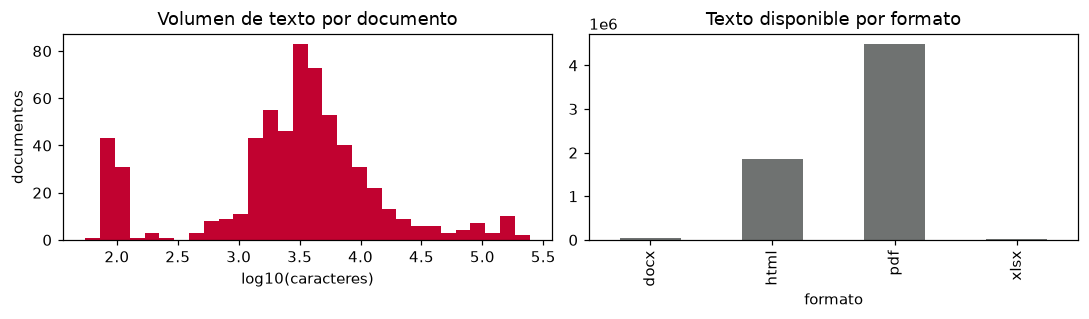

,archivo,caracteres,paginas
331,raw/html/eventos-utb.html,55,1
545,raw/html/profesores_royman-lopez.html,83,1
368,raw/html/profesores_silvana-junco.html,84,1
534,raw/html/profesores_rolando-ariza.html,84,1
99,raw/html/profesores_ascanio-ferreira.html,87,1


Los documentos más breves requieren distinguir entre páginas de navegación y extracciones incompletas.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(np.log10(datos['caracteres'].clip(lower=1)), bins=30, color=ROJO)
axes[0].set(title='Volumen de texto por documento', xlabel='log10(caracteres)', ylabel='documentos')
datos.groupby('formato')['caracteres'].sum().plot.bar(ax=axes[1], color=GRIS, title='Texto disponible por formato')
plt.tight_layout(); plt.show()
display(datos.sort_values('caracteres').head(5)[['archivo','caracteres','paginas']])
print('Los documentos más breves requieren distinguir entre páginas de navegación y extracciones incompletas.')

In [7]:
from scripts.extract_text import limpiar
for cifra in ['100', '50', '80', '3,20']:
    assert cifra in limpiar('Valor requerido\n' + cifra + '\npuntos'), 'La limpieza pierde cifras'
muestra = datos.groupby('formato', group_keys=False).sample(n=1, random_state=SEED)
ejemplos = []
for identificador in muestra['document_id']:
    doc = next(d for d in documentos if d['document_id'] == identificador)
    pagina = next(p for p in doc['paginas'] if p['texto'].strip())
    ejemplos.append({'documento': doc['titulo'], 'pagina': pagina.get('pagina'), 'texto': pagina['texto'][:650]})
display(pd.DataFrame(ejemplos))
print('Las pruebas de limpieza conservaron las cifras aisladas; la tabla muestra un ejemplo de texto por formato.')

,documento,pagina,texto
0,solicitud_convenio_desde_la_utb,NaN,SOLICITUD DE TRÁMITE DE CONVENIO\n\nFecha: | Solicitud N° *\n\n*Espacio para la Oficina de Internacionalización\n\nT...
1,Universidad Tecnológica de Bolívar - Se un gran profesional,NaN,"### Pregrados\n\n### Posgrados\n\n### Becas y finaciamiento\n\n### Cursos, diplomados y talleres\n\n### UTB Virtual\..."
2,Boleti_n-IDEEAS-No3,1.0,"BOLETÍN IDEEAS, No3/2021\n\nPobreza y desigualdad en 2020: balance en\nCartagena y las ciudades del Caribe colombian..."
3,FORMATO-SOLICITUD-INCENTIVO-AL-NUCLEO-FAMILIAR,NaN,Fila 6: SOLICITUD DE INCENTIVO DE CAPACITACIÓN AL GRUPO FAMILIAR | | | | | | | | | | | | | | | | | | | | | | | | | |...


Las pruebas de limpieza conservaron las cifras aisladas; la tabla muestra un ejemplo de texto por formato.


### Disponibilidad y calidad del texto
La carga permitió trabajar con 620 documentos y cerca de 6,42 millones de caracteres. De ellos, 409 son HTML y 202 son PDF. Los nueve restantes corresponden a textos de Word y Excel disponibles en la extracción previa. Los PDF aportan alrededor del 70 % del texto, a pesar de ser menos numerosos. La longitud también es desigual: la mediana es de 3.318 caracteres, mientras que el percentil 95 se aproxima a 43.228. Esta distribución hace conveniente dividir los documentos extensos y conservar completas las secciones breves.

El catálogo registra 68 archivos pendientes: 64 PDF, dos DOCX, un HTML y un DOC antiguo. Los primeros 67 no produjeron texto suficiente, pero ese diagnóstico por sí solo no establece la causa. En los PDF puede ser necesario reconocer texto contenido en imágenes, los archivos Word y HTML requieren revisar su estructura o el contenido descargado. El DOC antiguo necesita conversión. Otros nueve archivos quedaron en cuarentena y dos se reconocieron como duplicados durante el procesamiento.

La disponibilidad parcial también aparece dentro de los documentos aceptados, con 132 páginas marcadas para una posible revisión mediante OCR. Algunas pueden corresponder a imágenes o portadas, de modo que la marca sirve para priorizar la inspección. El número de documentos cargados describe el material utilizable, pero no garantiza que todos sus elementos hayan sido extraídos.

La revisión del preprocesamiento mostró, además, que eliminar líneas numéricas podía suprimir puntajes o valores de tablas. La limpieza conserva esas cifras y normaliza ligaduras tipográficas como `ﬁ`. Los hashes permiten comprobar la correspondencia con los originales. En conjunto, estos controles reducen alteraciones del contenido, aunque la revisión de una muestra no reemplaza el examen de los casos pendientes.

## 3. Fase 3 — Representación y modelado de la recuperación
La comparación utiliza dos representaciones del mismo texto: TF-IDF de palabras y bigramas como línea base, y embeddings con búsqueda por similitud coseno como alternativa semántica. Ambos métodos conservan los títulos y la procedencia de los fragmentos, de manera que las diferencias observadas se relacionen con la representación y la recuperación, no con disponer de corpus distintos.

La exploración de la fragmentación consideró ventanas de hasta 1.000 caracteres con solape de 120 y ventanas de hasta 1.600 con solape de 180. La primera produjo 11.473 fragmentos y la segunda 9.269. La reducción del número de unidades disminuye el volumen a representar, pero puede cambiar la cantidad de condiciones reunidas en cada fragmento. La división respeta páginas y encabezados; por ello, el tamaño máximo no equivale a una longitud uniforme.

La evaluación posterior se realizó con la configuración de 1.600/180 caracteres, que buscó conservar contexto sin aumentar excesivamente el número de vectores. La comparación entre tamaños fue descriptiva; no permite establecer cuál maximiza la recuperación. Esa selección requeriría consultas de desarrollo independientes del conjunto principal.

,max_caracteres,solape,fragmentos,mediana_chars,p95_chars
0,1000,120,11473,621.0,998.0
1,1600,180,9269,542.0,1598.0


,id,pagina,seccion,texto
0,98b7ef1d798f,0,# Conoce nuestra dirección de extensión - UTB,# Conoce nuestra dirección de extensión - UTB\n\n- Centro de Educación Permanente\n\n- Consultorías y asesorías\n\n-...
1,c74aff9221d0,0,## Dirección de Extensión,"## Dirección de Extensión\n\nBuscamos alcanzar la interacción e integración de las capacidades académicas, formativa..."
2,51538c2ab7a5,0,## Centro de Educación Permanente,"## Centro de Educación Permanente\n\nLa Universidad Tecnológica de Bolívar te brinda una amplia variedad de cursos, ..."
3,75557cf8e728,0,## Consultorías y asesorías,## Consultorías y asesorías\n\nLa función natural de la UTB se enfoca en la generación de conocimiento a través de s...


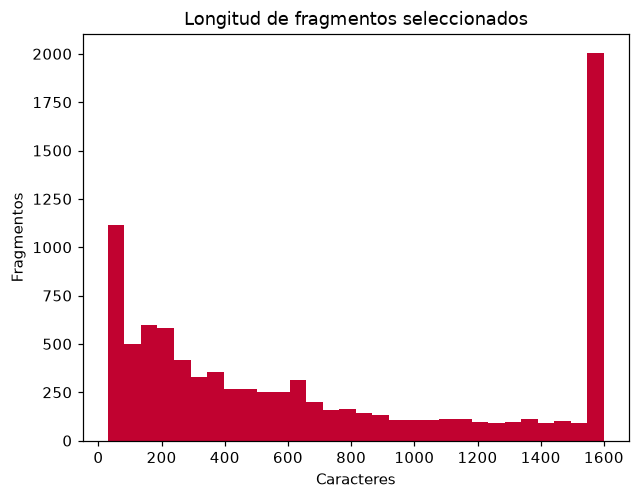

In [8]:
alternativas = []
for maximo, solape in [(1000, 120), (1600, 180)]:
    candidatos = fragmentar_documentos(documentos, max_caracteres=maximo, solape=solape)
    longitudes = np.array([len(f['text']) for f in candidatos])
    alternativas.append({'max_caracteres': maximo, 'solape': solape, 'fragmentos': len(candidatos),
                         'mediana_chars': float(np.median(longitudes)), 'p95_chars': float(np.percentile(longitudes,95))})
fragmentos = fragmentar_documentos(documentos, **FRAGMENTACION)
assert len({f['id'] for f in fragmentos}) == len(fragmentos)
assert all(f['metadata']['source_url'] and f['metadata']['source_hash'] for f in fragmentos)
assert max(len(f['text']) for f in fragmentos) <= FRAGMENTACION['max_caracteres']
display(pd.DataFrame(alternativas))
display(pd.DataFrame([{'id': f['id'][:12], 'pagina': f['metadata']['page'], 'seccion': f['metadata']['section'],
                      'texto': f['text'][:500]} for f in fragmentos[:4]]))
plt.hist([len(f['text']) for f in fragmentos], bins=30, color=ROJO)
plt.title('Longitud de fragmentos seleccionados'); plt.xlabel('Caracteres'); plt.ylabel('Fragmentos'); plt.show()

In [9]:
protocolo = {'modelo': identidad_modelo(), 'fragmentacion': FRAGMENTACION, 'seed': SEED,
    'k_principal': K, 'objetivo_recall': OBJETIVO_RECALL, 'preguntas_sha256': huella((ROOT / 'data/preguntas.csv').read_bytes()),
    'corpus_sha256': huella(sorted((d['document_id'], d['sha256_origen']) for d in documentos)),
    'evaluacion': 'TF-IDF frente a embeddings; localizadores automáticos no equivalen a evidencia humana verificada',
    'ubicacion': 'Cartagena, Colombia', 'country_iso_code': 'COL',
    'script_sha256': huella((ROOT / 'src/embeddings.py').read_bytes())}
protocolo_path = SALIDA / 'protocolo.json'
if protocolo_path.exists():
    anterior = json.loads(protocolo_path.read_text(encoding='utf-8'))
    claves = ['modelo','fragmentacion','preguntas_sha256','corpus_sha256']
    assert all(anterior[k] == protocolo[k] for k in claves), 'Cambió el experimento: usar otra SALIDA, no sobrescribir resultados'
else:
    guardar_json(protocolo_path, protocolo)
print('Configuración y huellas del experimento registradas. Semilla:', SEED)

Configuración y huellas del experimento registradas. Semilla: 42


In [10]:
if RECONSTRUIR or not (RUTA_INDICE / 'estado.json').exists():
    with medir('indexacion'):
        estado = construir_indice(fragmentos, cache_anterior=CACHE_ANTERIOR)
    guardar_json(SALIDA / 'indexacion.json', estado)
else:
    estado = json.loads((RUTA_INDICE / 'estado.json').read_text(encoding='utf-8'))
    firma_esperada = huella({'fragments': fragmentos, 'model': protocolo['modelo']['digest'], 'format': 'title-text-v1'})
    assert estado['fingerprint'] == firma_esperada, 'El corpus/configuración no corresponde al índice; reconstruir explícitamente'
    print('Índice persistente cargado con la configuración registrada.')
display(pd.DataFrame([{k: estado[k] for k in ['count','dimension','new','reused','legacy_reused','embedding_seconds','index_seconds']}]))
print('Los conteos de vectores nuevos y reutilizados corresponden a la construcción registrada del índice.')

Índice persistente cargado con la configuración registrada.


,count,dimension,new,reused,legacy_reused,embedding_seconds,index_seconds
0,9269,768,4875,4394,4146,190.028715,26.973232


Los conteos de vectores nuevos y reutilizados corresponden a la construcción registrada del índice.


In [11]:
with cargar_indice() as indice:
    assert indice.coleccion.count() == len(fragmentos)
    ejemplo_vector = indice.coleccion.get(limit=5, include=['embeddings','metadatas'])
    matriz_muestra = validar_vectores(ejemplo_vector['embeddings'], dimension=estado['dimension'])
print('Dimensión:', estado['dimension'], '| vectores:', estado['count'])
print('Normas euclídeas de la muestra:', np.linalg.norm(matriz_muestra, axis=1).round(5))
print('La construcción verificó que los vectores fueran finitos, no nulos y de dimensión uniforme.')

Dimensión: 768 | vectores: 9269
Normas euclídeas de la muestra: [1. 1. 1. 1. 1.]
La construcción verificó que los vectores fueran finitos, no nulos y de dimensión uniforme.


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
# TF-IDF utiliza el mismo título y texto que la representación documental mediante embeddings.
textos_indice = ['title: ' + f['metadata']['title'][:200] + ' | text: ' + f['text'] for f in fragmentos]
with medir('tfidf_ajuste'):
    tfidf = TfidfVectorizer(ngram_range=(1,2), strip_accents='unicode', sublinear_tf=True, max_features=80000)
    matriz_tfidf = tfidf.fit_transform(textos_indice)

def buscar_tfidf(pregunta, k=5):
    scores = (matriz_tfidf @ tfidf.transform([pregunta]).T).toarray().ravel()
    orden = np.argsort(-scores, kind='stable')[:k]
    return [{**fragmentos[i], 'similarity': float(scores[i])} for i in orden]

print('Matriz TF-IDF (fragmentos, características):', matriz_tfidf.shape, '| entradas no nulas:', matriz_tfidf.nnz)

[codecarbon INFO @ 23:13:04] offline tracker init
[codecarbon WARNING @ 23:13:04] Multiple instances of codecarbon are allowed to run at the same time.


Matriz TF-IDF (fragmentos, características): (9269, 80000) | entradas no nulas: 1210230


## 4. Fase 4 — Evaluación de la recuperación
### Alcance de los indicadores
El conjunto histórico contiene 57 preguntas: 47 declaradas como respondibles y diez sin respuesta documental. Las métricas de recuperación se calculan sobre las primeras, mientras que las negativas permiten examinar la diferencia entre afinidad temática y disponibilidad de una respuesta. Las tres repeticiones temporales por método miden estabilidad de ejecución sobre las mismas consultas. Como las preguntas ya habían sido examinadas, la comparación es retrospectiva.

HitFuente@5 indica si aparece el documento de referencia entre los cinco primeros resultados. La cobertura de localizadores considera los artículos o secciones citados en cada pregunta. Este segundo indicador es más específico, pero todavía aproxima la relevancia mediante la ubicación: un artículo recuperado puede omitir alguna condición necesaria para responder. El Recall@5 de evidencia completa permanece pendiente de revisar esas unidades de información.

La auditoría identifica diferencias entre la URL registrada del reglamento y la de la copia disponible, además de una referencia externa de ICETEX que requiere validación. También falta texto utilizable de una resolución de becas citada en 13 preguntas. Su ausencia afecta la recuperación del documento esperado y obliga a distinguir las carencias del corpus de los errores de selección.

Los resultados muestran un comportamiento mixto. Los embeddings alcanzan una cobertura de localizadores del 54,3 %, frente al 46,8 % de TF-IDF. En cambio, TF-IDF recupera la fuente de referencia en el 66,0 % de las preguntas respondibles y los embeddings en el 55,3 %. La consulta vectorial tarda aproximadamente 0,240 segundos en promedio, frente a 0,009 segundos del método léxico. La alternativa semántica mejora uno de los indicadores, pero no ofrece una ventaja uniforme en recuperación y costo.

In [13]:
def normalizar(texto):
    return ''.join(c for c in unicodedata.normalize('NFKD', texto.lower()) if not unicodedata.combining(c))

def referencia_sugerida(fila):
    exactos = [d for d in documentos if fila.fuente_url in d['urls']]
    candidatos = exactos or [d for d in documentos if Path(d['archivo_origen']).name == fila.fuente_url.rsplit('/',1)[-1]]
    articulos = list(dict.fromkeys(re.findall(r'art(?:iculo)?\.?\s*(\d+)', normalizar(fila.pagina_o_seccion))))
    return {'documentos': [d['document_id'] for d in candidatos], 'articulos': articulos,
            'estado_fuente': 'exacta' if exactos else 'alias_candidato' if candidatos else 'no_disponible',
            'negativa': fila.tiene_respuesta == 'no'}

referencias = {fila.id: referencia_sugerida(fila) for fila in preguntas.itertuples()}
auditoria_referencias = pd.DataFrame([{'id': fila.id, 'categoria': fila.categoria,
    'tiene_respuesta': fila.tiene_respuesta, 'estado_fuente': referencias[fila.id]['estado_fuente'],
    'articulos': ', '.join(referencias[fila.id]['articulos'])} for fila in preguntas.itertuples()])
display(auditoria_referencias.groupby(['tiene_respuesta','estado_fuente']).size().rename('preguntas').to_frame())
display(auditoria_referencias[auditoria_referencias['estado_fuente'] != 'exacta'].head(18))
auditoria_referencias.to_csv(SALIDA / 'auditoria_referencias.csv', index=False, encoding='utf-8-sig')

preguntas
tiene_respuesta estado_fuente             
no              alias_candidato         10
si              alias_candidato         29
                exacta                   4
                no_disponible           14

,id,categoria,tiene_respuesta,estado_fuente,articulos
0,1,calificaciones,si,alias_candidato,51
1,2,estados_academicos,si,alias_candidato,68
2,3,asistencia,si,alias_candidato,67
3,4,matricula,si,alias_candidato,39
4,5,sin_respuesta,no,alias_candidato,110
5,6,becas_financiacion,si,no_disponible,1
6,7,becas_financiacion,si,no_disponible,1
7,8,becas_financiacion,si,no_disponible,2
8,9,becas_financiacion,si,no_disponible,2
9,10,becas_financiacion,si,no_disponible,2


In [14]:
resultados_path = SALIDA / 'consultas.json'
marca_consultas = huella([estado['fingerprint'], protocolo['preguntas_sha256'], REPETICIONES_TIEMPO, 'tfidf-word-1-2-80000-v1'])
if resultados_path.exists() and not RECALCULAR_CONSULTAS:
    guardado = json.loads(resultados_path.read_text(encoding='utf-8'))
    assert guardado['signature'] == marca_consultas, 'Los resultados guardados pertenecen a otra configuración'
    consultas = guardado['rows']
    print('La evaluación utiliza las consultas y los tiempos guardados para esta configuración.')
else:
    consultas = []
    for metodo in ['tfidf', 'embeddings']:
        with cargar_indice() as indice:
            buscador = buscar_tfidf if metodo == 'tfidf' else lambda q, k: indice.buscar(q, k=k, usar_cache=False)
            with medir('calentamiento_' + metodo):
                buscador('¿Qué información institucional puedo consultar?', K)
            with medir('consultas_' + metodo):
                for repeticion in range(REPETICIONES_TIEMPO):
                    for fila in preguntas.itertuples():
                        inicio = time.perf_counter()
                        top = buscador(fila.pregunta, K)
                        consultas.append({'id': fila.id, 'metodo': metodo, 'repeticion': repeticion,
                            'latencia_s': time.perf_counter() - inicio, 'top': top})
                    print(metodo, 'repetición', repeticion + 1, 'de', REPETICIONES_TIEMPO)
    guardar_json(resultados_path, {'signature': marca_consultas, 'rows': consultas})
print('Registros de recuperación:', len(consultas))

La evaluación utiliza las consultas y los tiempos guardados para esta configuración.
Registros de recuperación: 342


In [15]:
def indicadores_localizadores(registro, k=5):
    ref = referencias[registro['id']]
    top = registro['top'][:k]
    fuentes = [r for r in top if r['metadata']['document_id'] in ref['documentos']]
    hit = float(bool(fuentes))
    if ref['articulos']:
        cubiertos = [any(re.search(r'articulo\s+' + articulo + r'(?!\d)', normalizar(r['metadata']['section'])) for r in fuentes) for articulo in ref['articulos']]
        cobertura = float(np.mean(cubiertos))
    else:
        cobertura = hit
    return hit, cobertura

filas_resultado = []
for c in consultas:
    if c['repeticion'] != 0:
        continue
    fila = preguntas.set_index('id').loc[c['id']]
    hit, cobertura = indicadores_localizadores(c)
    filas_resultado.append({'id': c['id'], 'metodo': c['metodo'], 'categoria': fila.categoria,
        'tiene_respuesta': fila.tiene_respuesta, 'estado_fuente': referencias[c['id']]['estado_fuente'],
        'hit_fuente_5': hit, 'cobertura_localizadores_5': cobertura, 'latencia_s': c['latencia_s'],
        'score_top1': c['top'][0]['similarity'], 'top_ids': json.dumps([r['id'] for r in c['top']])})
resultados = pd.DataFrame(filas_resultado)
positivos = resultados[resultados['tiene_respuesta'] == 'si']
resumen_proxy = positivos.groupby('metodo').agg(n=('id','size'), hit_fuente_5=('hit_fuente_5','mean'),
    cobertura_localizadores_5=('cobertura_localizadores_5','mean'))
tiempos = pd.DataFrame([{k: c[k] for k in ['metodo','repeticion','latencia_s']} for c in consultas])
resumen_tiempo = tiempos.groupby('metodo')['latencia_s'].agg(media_s='mean', mediana_s='median', p95_s=lambda x: x.quantile(.95))
display(resumen_proxy.round(3)); display(resumen_tiempo.round(4))
print('Los indicadores resumen la recuperación de fuentes y artículos entre los cinco primeros resultados.')
resultados.to_csv(SALIDA / 'resultados_recuperacion.csv', index=False, encoding='utf-8-sig')

,n,hit_fuente_5,cobertura_localizadores_5
metodo,,,
embeddings,47,0.553,0.543
tfidf,47,0.660,0.468


,media_s,mediana_s,p95_s
metodo,,,
embeddings,0.2405,0.2176,0.3207
tfidf,0.0093,0.0089,0.0117


Los indicadores resumen la recuperación de fuentes y artículos entre los cinco primeros resultados.


In [16]:
# Unidades de evidencia sugeridas a partir de los localizadores de referencia.
revision_path = SALIDA / 'revision_evidencias.csv'
if not revision_path.exists():
    revision = []
    for fila in preguntas.itertuples():
        if fila.tiene_respuesta != 'si':
            continue
        ref = referencias[fila.id]
        unidades = ref['articulos'] or ['documento: dividir en condiciones necesarias al revisar']
        for unidad in unidades:
            candidatos = [f['id'] for f in fragmentos if f['metadata']['document_id'] in ref['documentos'] and
                (not ref['articulos'] or re.search(r'articulo\s+' + unidad + r'(?!\d)', normalizar(f['metadata']['section'])))]
            revision.append({'id': fila.id, 'unidad_evidencia': unidad, 'chunk_ids': json.dumps(candidatos),
                'verificado': 'no', 'revisor': '', 'observacion': 'Propuesta por localizador; revisar que cubra realmente la condición requerida'})
    pd.DataFrame(revision).to_csv(revision_path, index=False, encoding='utf-8-sig')
revision = pd.read_csv(revision_path, dtype={'id':str}, keep_default_na=False, encoding='utf-8-sig')
ids_positivos = set(preguntas.loc[preguntas['tiene_respuesta'] == 'si','id'])
evidencia_lista = (set(revision['id']) == ids_positivos and revision['verificado'].eq('si').all()
                   and revision['revisor'].str.strip().ne('').all()
                   and revision['chunk_ids'].map(lambda x: bool(json.loads(x))).all())
metricas_evidencia = {}
if evidencia_lista:
    for metodo in ['tfidf','embeddings']:
        valores = []
        for c in consultas:
            if c['metodo'] != metodo or c['repeticion'] != 0 or c['id'] not in ids_positivos:
                continue
            recuperados = {r['id'] for r in c['top'][:K]}
            unidades = revision[revision['id'] == c['id']]
            valores.append(np.mean([bool(recuperados.intersection(json.loads(r.chunk_ids))) for r in unidades.itertuples()]))
        metricas_evidencia[metodo] = float(np.mean(valores))
print('Recall@5 de evidencia completa:', metricas_evidencia if evidencia_lista else 'sin estimación; las unidades propuestas aún no han sido verificadas.')

Recall@5 de evidencia completa: sin estimación; las unidades propuestas aún no han sido verificadas.


### 4.1 Incertidumbre de la diferencia de cobertura
El bootstrap pareado estima la variación de la diferencia entre métodos conservando la correspondencia de cada pregunta. La diferencia observada en cobertura de localizadores es de 7,45 puntos porcentuales a favor de los embeddings, con un intervalo del 95 % entre −8,51 y 22,37 puntos. El intervalo incluye cero y diferencias de ambos signos, por lo que la ventaja puntual no basta para establecer una superioridad concluyente.

La concentración de preguntas en determinados documentos y la repetición de artículos limitan la independencia de las observaciones. Las repeticiones temporales describen el rendimiento de ejecución, pero el conjunto de evaluación sigue formado por las mismas preguntas.

Diferencia de cobertura de localizadores (embeddings - TF-IDF): 7.45 puntos porcentuales
Intervalo bootstrap del 95 %: [-8.51 22.37] puntos porcentuales


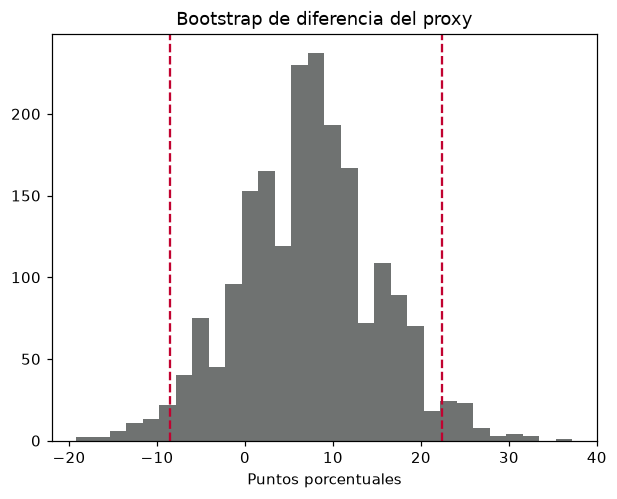

In [17]:
pares = positivos.pivot(index='id', columns='metodo', values='cobertura_localizadores_5').sort_index()
diferencias = (pares['embeddings'] - pares['tfidf']).to_numpy()
rng = np.random.default_rng(SEED)
bootstrap = np.array([rng.choice(diferencias, size=len(diferencias), replace=True).mean() for _ in range(2000)])
ic = np.quantile(bootstrap, [.025,.975])
print('Diferencia de cobertura de localizadores (embeddings - TF-IDF):', round(diferencias.mean()*100,2), 'puntos porcentuales')
print('Intervalo bootstrap del 95 %:', (ic*100).round(2), 'puntos porcentuales')
plt.hist(bootstrap*100, bins=30, color=GRIS)
for limite in ic*100: plt.axvline(limite, color=ROJO, linestyle='--')
plt.title('Bootstrap de diferencia del proxy'); plt.xlabel('Puntos porcentuales'); plt.show()

### 4.2 Comparación pareada de la recuperación de fuentes
La prueba exacta de McNemar compara los casos en que solamente uno de los métodos recupera la fuente esperada. Se aplica a HitFuente@5, que es binario, y responde a una pregunta distinta del bootstrap de cobertura de artículos. El valor obtenido, p = 0,125, no permite rechazar la igualdad de probabilidades de acierto al nivel convencional de 0,05. Esto refleja evidencia insuficiente para esa diferencia en la muestra, no una demostración de equivalencia entre métodos.

In [18]:
from statsmodels.stats.contingency_tables import mcnemar
hits = positivos.pivot(index='id', columns='metodo', values='hit_fuente_5').astype(bool)
a, b = hits['tfidf'].to_numpy(), hits['embeddings'].to_numpy()
tabla = [[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]]
p_value = float(mcnemar(tabla, exact=True).pvalue)
display(pd.DataFrame(tabla, index=['TF-IDF sí','TF-IDF no'], columns=['Embeddings sí','Embeddings no']))
print('Prueba exacta de McNemar: p =', p_value)

,Embeddings sí,Embeddings no
TF-IDF sí,25,6
TF-IDF no,1,15


Prueba exacta de McNemar: p = 0.125


### 4.3 Similitud y disponibilidad de información
La similitud del primer resultado tiende a ser mayor en las preguntas declaradas como respondibles: su mediana es aproximadamente 0,692, frente a 0,573 en las negativas. Sin embargo, las distribuciones se superponen. Algunas consultas sin respuesta obtienen puntuaciones cercanas a las de preguntas respondibles, lo que impide interpretar la similitud como una probabilidad de corrección.

Una consulta sobre cuántos estudiantes fueron sancionados puede recuperar el reglamento que describe las sanciones. La relación temática es pertinente, pero el documento puede carecer de las estadísticas solicitadas. La suficiencia de la información depende del contenido de los pasajes y no únicamente de la distancia entre vectores.

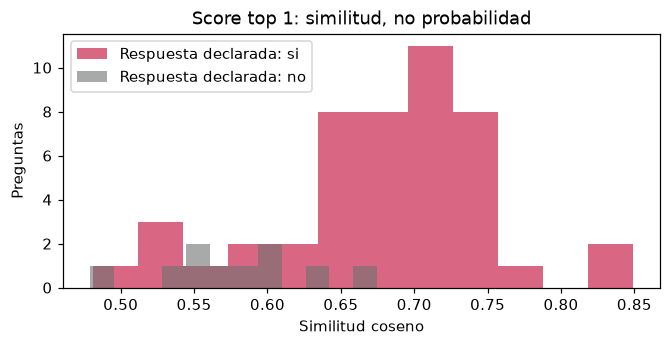

,id,score_top1,hit_fuente_5
61,5,0.479227,1.0
102,46,0.563326,1.0
106,50,0.540017,1.0
107,51,0.558981,1.0
108,52,0.601008,0.0
109,53,0.674857,1.0
110,54,0.605050,0.0
111,55,0.581752,1.0
112,56,0.556450,1.0
113,57,0.628761,0.0


La superposición de similitudes entre preguntas respondibles y negativas limita su uso como criterio de suficiencia.


In [19]:
fig, ax = plt.subplots(figsize=(7,3))
for tipo, color in [('si',ROJO),('no',GRIS)]:
    sub = resultados[(resultados['metodo'] == 'embeddings') & (resultados['tiene_respuesta'] == tipo)]
    ax.hist(sub['score_top1'], bins=12, alpha=.6, color=color, label='Respuesta declarada: ' + tipo)
ax.set(title='Score top 1: similitud, no probabilidad', xlabel='Similitud coseno', ylabel='Preguntas'); ax.legend(); plt.show()
display(resultados[(resultados['metodo'] == 'embeddings') & (resultados['tiene_respuesta'] == 'no')][['id','score_top1','hit_fuente_5']])
print('La superposición de similitudes entre preguntas respondibles y negativas limita su uso como criterio de suficiencia.')

### 4.4 Diferencias por categoría
La recuperación varía entre temas. En estados académicos, la cobertura de localizadores es del 100 % con embeddings y del 58,3 % con TF-IDF, sobre seis preguntas. En calificaciones ocurre lo contrario: TF-IDF alcanza el 100 % y los embeddings el 50 %, aunque la categoría contiene solamente dos casos. Los resultados de categorías tan pequeñas describen esos ejemplos y ofrecen poca base para generalizar.

En becas y financiación ambos métodos alcanzan el 17,6 %. Este resultado coincide con la falta de texto de una resolución utilizada en buena parte de las referencias de esa categoría. La diferencia entre temas, por tanto, no depende exclusivamente del tipo de representación; también intervienen la disponibilidad y la calidad del conocimiento indexado.

n  cobertura_proxy
categoria          metodo                         
admisiones         embeddings   5            0.400
                   tfidf        5            0.400
asistencia         embeddings   2            1.000
                   tfidf        2            0.000
becas_financiacion embeddings  17            0.176
                   tfidf       17            0.176
calificaciones     embeddings   2            0.500
                   tfidf        2            1.000
distinciones       embeddings   4            0.750
                   tfidf        4            0.500
estados_academicos embeddings   6            1.000
                   tfidf        6            0.583
general            embeddings   1            1.000
                   tfidf        1            1.000
ingles             embeddings   1            0.000
                   tfidf        1            1.000
matricula          embeddings   7            0.786
                   tfidf        7            0.786
web_becas          embeddings   2            1.000
                   tfidf        2            1.000

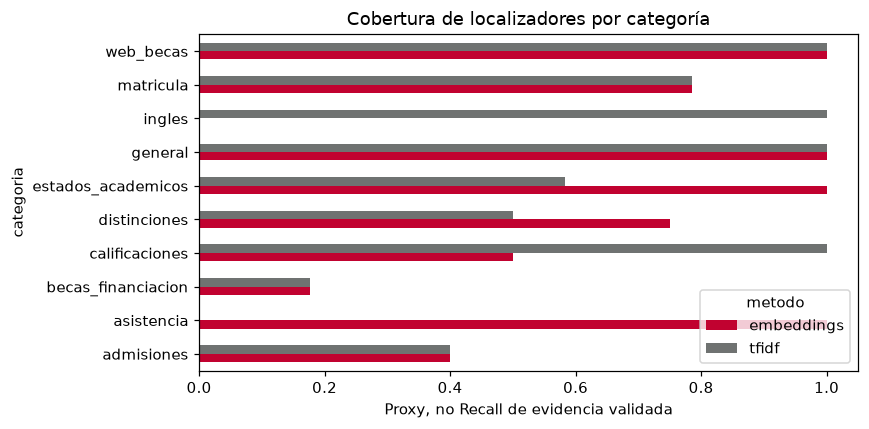

In [20]:
por_categoria = positivos.groupby(['categoria','metodo']).agg(n=('id','size'), cobertura_proxy=('cobertura_localizadores_5','mean'))
display(por_categoria.round(3))
por_categoria['cobertura_proxy'].unstack('metodo').plot.barh(figsize=(8,4), color=[ROJO,GRIS], title='Cobertura de localizadores por categoría')
plt.xlabel('Proxy, no Recall de evidencia validada'); plt.tight_layout(); plt.show()
por_categoria.to_csv(SALIDA / 'metricas_por_categoria.csv', encoding='utf-8-sig')

### 4.5 Cobertura según el número de fragmentos recuperados
La comparación entre los primeros uno, tres y cinco resultados permite observar cuánto aporta ampliar la selección. Los valores proceden de los mismos rankings, manteniendo k = 5 como configuración principal. Incluir más fragmentos aumenta las oportunidades de cubrir los localizadores, pero también puede añadir contenido redundante o menos pertinente. Para una generación posterior, esa ampliación supone más contexto que procesar y no garantiza una respuesta más completa.

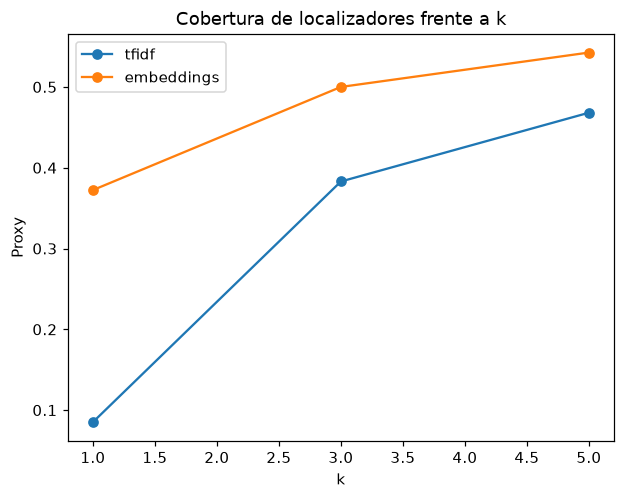

In [21]:
curva = []
for metodo in ['tfidf','embeddings']:
    for k in [1,3,5]:
        registros = [c for c in consultas if c['metodo'] == metodo and c['repeticion'] == 0 and c['id'] in ids_positivos]
        curva.append({'metodo':metodo, 'k':k, 'cobertura_proxy':np.mean([indicadores_localizadores(c,k)[1] for c in registros])})
curva = pd.DataFrame(curva)
for metodo in ['tfidf','embeddings']:
    sub = curva[curva['metodo'] == metodo]
    plt.plot(sub['k'],sub['cobertura_proxy'],'o-',label=metodo)
plt.title('Cobertura de localizadores frente a k'); plt.xlabel('k'); plt.ylabel('Proxy'); plt.legend(); plt.show()

### 4.6 Estado de la validación
El índice contiene los vectores correspondientes a todos los fragmentos aceptados y conserva su procedencia. Las comprobaciones de dimensión, valores finitos y persistencia respaldan su integridad técnica. La disponibilidad del corpus, en cambio, continúa limitada por los documentos y páginas pendientes de revisión.

La meta de Recall@5 del 80 % todavía no puede contrastarse con evidencia completa: las unidades sugeridas requieren validación de su contenido. Por ello, el resultado técnico y la utilidad documental se presentan como aspectos separados. La exactitud y la fidelidad de las respuestas generadas quedan reservadas a una evaluación del sistema RAG completo.

In [22]:
controles = [
    {'control':'Índice completo respecto de fragmentos aceptados', 'estado':'APROBADO' if estado['count'] == len(fragmentos) else 'FALLA'},
    {'control':'Vectores finitos, no nulos y dimensión homogénea', 'estado':'APROBADO'},
    {'control':'Fuentes trazables en todos los fragmentos', 'estado':'APROBADO'},
    {'control':'Todo el corpus descargado extraído', 'estado':'PENDIENTE: consultar faltantes/OCR'},
    {'control':'Recall@5 de evidencia >=80%', 'estado': ('APROBADO' if metricas_evidencia['embeddings'] >= OBJETIVO_RECALL else 'NO APROBADO') if evidencia_lista else 'INCOMPLETO: faltan relevancias verificadas'},
    {'control':'Exactitud/fidelidad/alucinación del chatbot', 'estado':'FUERA DE ESTE COMPONENTE; experimento del equipo'}]
display(pd.DataFrame(controles))
guardar_json(SALIDA / 'metricas.json', {'seed':SEED, 'k':K, 'evidence_verified': bool(evidencia_lista),
    'recall_at_5_evidence':metricas_evidencia, 'proxy_metrics':resumen_proxy.reset_index().to_dict('records'),
    'latency':resumen_tiempo.reset_index().to_dict('records'), 'bootstrap_proxy_ci95_pp':(ic*100).tolist(),
    'mcnemar_source_hit_p':p_value, 'gate':controles})

,control,estado
0,Índice completo respecto de fragmentos aceptados,APROBADO
1,"Vectores finitos, no nulos y dimensión homogénea",APROBADO
2,Fuentes trazables en todos los fragmentos,APROBADO
3,Todo el corpus descargado extraído,PENDIENTE: consultar faltantes/OCR
4,Recall@5 de evidencia >=80%,INCOMPLETO: faltan relevancias verificadas
5,Exactitud/fidelidad/alucinación del chatbot,FUERA DE ESTE COMPONENTE; experimento del equipo


## 5. Pruebas de comportamiento
Las pruebas inspiradas en CheckList examinan la sensibilidad de la recuperación ante cambios de escritura y contexto. Se modificaron tres preguntas mediante mayúsculas y eliminación de tildes, errores tipográficos y la adición de una frase irrelevante. La similitud de Jaccard resume cuánto coincide el conjunto de cinco fragmentos antes y después del cambio.

Los errores tipográficos conservaron una parte importante de los resultados en estos ejemplos. La frase sobre el clima produjo un efecto más marcado: en las consultas de cursos y biblioteca, los dos conjuntos quedaron completamente separados. Esto sugiere sensibilidad a información accesoria, aunque fragmentos distintos pueden seguir siendo útiles. La revisión del contenido resulta necesaria para distinguir cambios de selección de pérdidas reales de relevancia.

El análisis de errores muestra ocho casos de cada método con cobertura incompleta de localizadores. Todos corresponden a fuentes localizadas mediante alias candidatos, cuya identidad requiere confirmación antes de atribuir las omisiones exclusivamente al ranking. Estos ejemplos orientan la revisión de la fragmentación y la selección de pasajes. Las preguntas cuya fuente carece de texto utilizable, identificadas en la auditoría general, requieren primero completar la extracción.

In [23]:
robustez_path = SALIDA / 'robustez.json'
if robustez_path.exists() and not RECALCULAR_CONSULTAS:
    robustez = json.loads(robustez_path.read_text(encoding='utf-8'))
else:
    robustez = []
    bases = ['¿Dónde puedo consultar cursos y diplomados?', '¿Qué servicios ofrece la biblioteca?', '¿Qué porcentaje cubre la Beca Legacy UTB?']
    with cargar_indice() as indice:
        with medir('robustez'):
            for base in bases:
                original = {r['id'] for r in indice.buscar(base)}
                variantes = {'mayus_sin_tildes':normalizar(base).upper(),
                    'frase_irrelevante':base + ' Hoy hace calor en Cartagena.',
                    'error_escritura':base.replace('puedo','puedoo').replace('biblioteca','bibliteca').replace('porcentaje','porcentje')}
                for nombre, variante in variantes.items():
                    alterados = {r['id'] for r in indice.buscar(variante)}
                    robustez.append({'pregunta':base, 'prueba':nombre,
                        'jaccard_top5':len(original & alterados) / len(original | alterados)})
    guardar_json(robustez_path,robustez)
display(pd.DataFrame(robustez))

,pregunta,prueba,jaccard_top5
0,¿Dónde puedo consultar cursos y diplomados?,mayus_sin_tildes,0.428571
1,¿Dónde puedo consultar cursos y diplomados?,frase_irrelevante,0.000000
2,¿Dónde puedo consultar cursos y diplomados?,error_escritura,1.000000
3,¿Qué servicios ofrece la biblioteca?,mayus_sin_tildes,0.666667
4,¿Qué servicios ofrece la biblioteca?,frase_irrelevante,0.000000
5,¿Qué servicios ofrece la biblioteca?,error_escritura,0.666667
6,¿Qué porcentaje cubre la Beca Legacy UTB?,mayus_sin_tildes,0.666667
7,¿Qué porcentaje cubre la Beca Legacy UTB?,frase_irrelevante,0.666667
8,¿Qué porcentaje cubre la Beca Legacy UTB?,error_escritura,1.000000


In [24]:
errores = positivos[positivos['cobertura_localizadores_5'] < 1].copy()
errores['tipo_error'] = np.where(errores['estado_fuente'] == 'no_disponible',
    'Fuente no disponible en texto / referencia pendiente', 'Localizador no cubierto completamente en top 5')
errores['hipotesis'] = np.where(errores['estado_fuente'] == 'no_disponible',
    'Revisar extracción/OCR y validez de la referencia antes de culpar al embedding',
    'Revisar fragmentación, continuidad de artículo y ranking; requiere inspeccionar el texto')
# La muestra incluye ocho casos de cada método y prioriza fuentes con texto disponible.
errores['prioridad_revision'] = errores['estado_fuente'].ne('no_disponible').astype(int)
seleccion = errores.sort_values(['metodo','prioridad_revision'], ascending=[True,False]).groupby('metodo', group_keys=False).head(8)
casos = seleccion.merge(preguntas[['id','pregunta','pagina_o_seccion']], on='id')
top_por_caso = {(c['id'], c['metodo']): c['top'][0] for c in consultas if c['repeticion'] == 0}
casos['top1_seccion'] = [top_por_caso[(r.id,r.metodo)]['metadata']['section'] for r in casos.itertuples()]
casos['top1_fragmento'] = [top_por_caso[(r.id,r.metodo)]['text'][:500] for r in casos.itertuples()]
display(casos[['id','metodo','pregunta','tipo_error','hipotesis']])
casos.to_csv(SALIDA / 'analisis_errores.csv', index=False, encoding='utf-8-sig')
print('Casos con cobertura incompleta seleccionados para revisión:', len(casos))

,id,metodo,pregunta,tipo_error,hipotesis
0,1,embeddings,¿Cuál es la calificación mínima aprobatoria para un curso de pregrado en la UTB?,Localizador no cubierto completamente en top 5,"Revisar fragmentación, continuidad de artículo y ranking; requiere inspeccionar el texto"
1,23,embeddings,¿Es requisito demostrar nivel B2 de inglés para graduarse de un programa de pregrado presencial en la UTB?,Localizador no cubierto completamente en top 5,"Revisar fragmentación, continuidad de artículo y ranking; requiere inspeccionar el texto"
2,34,embeddings,¿Hasta qué semana puede retirar cursos un estudiante de pregrado virtual en cada ciclo?,Localizador no cubierto completamente en top 5,"Revisar fragmentación, continuidad de artículo y ranking; requiere inspeccionar el texto"
3,38,embeddings,¿Cuáles son los requisitos para inscribirse por primera vez a un programa de pregrado de la UTB?,Localizador no cubierto completamente en top 5,"Revisar fragmentación, continuidad de artículo y ranking; requiere inspeccionar el texto"
4,39,embeddings,¿Cuáles son los tipos de admisión para programas de pregrado y posgrado en la UTB?,Localizador no cubierto completamente en top 5,"Revisar fragmentación, continuidad de artículo y ranking; requiere inspeccionar el texto"
5,40,embeddings,¿Quién no puede solicitar reingreso a la UTB?,Localizador no cubierto completamente en top 5,"Revisar fragmentación, continuidad de artículo y ranking; requiere inspeccionar el texto"
6,43,embeddings,¿Un estudiante sancionado puede recibir distinciones académicas de la UTB?,Localizador no cubierto completamente en top 5,"Revisar fragmentación, continuidad de artículo y ranking; requiere inspeccionar el texto"
7,45,embeddings,¿Cuáles son las condiciones para que un estudiante de pregrado cursa un segundo programa en doble programa?,Localizador no cubierto completamente en top 5,"Revisar fragmentación, continuidad de artículo y ranking; requiere inspeccionar el texto"
8,2,tfidf,¿Qué Promedio Ponderado Acumulado (PPA) debe mantener un estudiante de pregrado y qué pasa si al finalizar un period...,Localizador no cubierto completamente en top 5,"Revisar fragmentación, continuidad de artículo y ranking; requiere inspeccionar el texto"
9,3,tfidf,¿Qué porcentaje mínimo de asistencia se exige en la modalidad presencial y qué ocurre si no se cumple?,Localizador no cubierto completamente en top 5,"Revisar fragmentación, continuidad de artículo y ranking; requiere inspeccionar el texto"


Casos con cobertura incompleta seleccionados para revisión: 16


## 6. Fase 5 — Exportación y persistencia
La persistencia permite utilizar el corpus vectorizado en ejecuciones posteriores sin repetir la inferencia documental. La prueba de recarga recuperó los 9.269 registros y conservó los valores de la muestra de vectores comparada. Con ello se verificó la continuidad entre el índice construido y el que se consulta después.

El índice conserva texto, ubicación y procedencia, junto con la identidad del modelo y la huella de configuración. Estas referencias permiten asociar cada recuperación con la versión procesada. La base activa se mantiene fuera de la carpeta sincronizada para reducir conflictos de escritura, y su reutilización presupone el mismo modelo y preprocesamiento.

In [25]:
with cargar_indice() as recargado:
    conteo_recargado = recargado.coleccion.count()
    muestra_recargada = recargado.coleccion.get(limit=5, include=['embeddings'])['embeddings']
assert conteo_recargado == estado['count']
assert np.allclose(matriz_muestra, muestra_recargada), 'Cambió el orden/contenido de la muestra persistida'
print('La recarga conservó el número de registros y los valores de la muestra de vectores.')
print('Ubicación del índice persistente:', RUTA_INDICE)
print('Huella de configuración y contenido:', estado['fingerprint'])

La recarga conservó el número de registros y los valores de la muestra de vectores.
Ubicación del índice persistente: C:\Users\mjuli\AppData\Local\ToolIA-Bot\crisp_vectorial
Huella de configuración y contenido: a69246560dd6d0085e40facfbdd01c192d2e45c2a3f79bc38a89410bd6c7ccc2


## 7. Integración del componente de recuperación
La implementación reutilizable se concentra en `src/embeddings.py`. La función `cargar_indice()` abre la base persistida y `buscar(pregunta, k=5)` devuelve identificador, texto, metadatos y similitud de cada resultado. Este contrato permite utilizar la misma recuperación fuera del entorno exploratorio.

El ejemplo de asistencia muestra cómo los fragmentos se relacionan con un documento, una página y una sección. Un generador de respuestas puede consumir esa información como contexto y conservar la procedencia para las citas. La consulta del índice y la interpretación de los pasajes siguen siendo operaciones diferentes: disponer de una fuente pertinente no determina cómo se redactará la respuesta.

In [26]:
# El ejemplo utiliza una consulta guardada del conjunto de evaluación.
demo = next(c for c in consultas if c['metodo'] == 'embeddings' and c['repeticion'] == 0 and c['id'] == '3')
display(pd.DataFrame([{'ranking':i+1, 'score':r['similarity'], 'documento':r['metadata']['title'],
    'pagina':r['metadata']['page'], 'seccion':r['metadata']['section'], 'url':r['metadata']['source_url'],
    'fragmento':r['text'][:600]} for i,r in enumerate(demo['top'])]))
print('Los fragmentos conservan la procedencia necesaria para construir el contexto y las citas de una respuesta.')

,ranking,score,documento,pagina,seccion,url,fragmento
0,1,0.715577,Reglamento-Estudiantil-2026-actualizado_compressed,25,ARTÍCULO 67: Un estudiante de modalidad presencial deberá asistir como mínimo al 80% de,https://www.utb.edu.co/wp-content/uploads/2024/05/Reglamento-Estudiantil-2026-actualizado_compressed.pdf,ARTÍCULO 67: Un estudiante de modalidad presencial deberá asistir como mínimo al 80% de\nlas sesiones de clase y no ...
1,2,0.707644,Reglamento-Estudiantil-2026,25,ARTÍCULO 67: Un estudiante de modalidad presencial deberá asistir como mínimo al 80% de,https://www.utb.edu.co/wp-content/uploads/2026/10/Reglamento-Estudiantil-2026.pdf,ARTÍCULO 67: Un estudiante de modalidad presencial deberá asistir como mínimo al 80% de\nlas sesiones de clase y no ...
2,3,0.559545,MEMORANDO-MATRICULA-2021-2P-1,2,,https://www.utb.edu.co/wp-content/uploads/2021/07/MEMORANDO-MATRICULA-2021-2P-1.pdf,4. Clases Presenciales: esta modalidad se desarrolla con base en encuentros presenciales entre\n estudiantes y profe...
3,4,0.554314,Reglamento-Estudiantil-2026-actualizado_compressed,25,ARTÍCULO 66: La asistencia puntual a las sesiones académicas durante el período académico es,https://www.utb.edu.co/wp-content/uploads/2024/05/Reglamento-Estudiantil-2026-actualizado_compressed.pdf,ARTÍCULO 66: La asistencia puntual a las sesiones académicas durante el período académico es\nobligatoria y los prof...
4,5,0.544993,Reglamento-Estudiantil-2026,25,ARTÍCULO 66: La asistencia puntual a las sesiones académicas durante el período académico es,https://www.utb.edu.co/wp-content/uploads/2026/10/Reglamento-Estudiantil-2026.pdf,ARTÍCULO 66: La asistencia puntual a las sesiones académicas durante el período académico es\nobligatoria y los prof...


Los fragmentos conservan la procedencia necesaria para construir el contexto y las citas de una respuesta.


## 8. Fase 6 — Monitoreo y actualización
La vigencia del índice depende de que los cambios documentales se reflejen en la información recuperada. Para comprobar ese comportamiento se utilizó un calendario sintético y no oficial: la fecha de cierre del ejercicio cambió del 15 al 22 de enero de 2030. Tras la actualización, la consulta devolvió el dato nuevo y dejó de recuperar el anterior en la versión activa.

La repetición del procesamiento sin cambios no generó embeddings nuevos. Este comportamiento permite reutilizar cálculos cuando el contenido permanece estable. El ensayo se limita al índice local; la detección periódica de modificaciones en el sitio institucional corresponde al proceso que suministra los documentos.

In [27]:
monitor_path = SALIDA / 'actualizacion_sintetica.json'
if monitor_path.exists() and not RECALCULAR_CONSULTAS:
    monitor = json.loads(monitor_path.read_text(encoding='utf-8'))
else:
    temp_base = Path(os.environ.get('LOCALAPPDATA','.')) / 'Temp/opencode'
    temp_base.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix='crisp_fixture_',dir=temp_base) as temporal:
        ruta_prueba = Path(temporal) / 'chroma'
        doc_prueba = {'document_id':'fixture', 'titulo':'Calendario sintético NO OFICIAL',
            'archivo_origen':'fixture.html', 'fuente_url':'https://www.utb.edu.co/prueba-no-oficial/',
            'sha256_origen':'fixture-v1', 'paginas':[{'pagina':None,
            'texto':'Ejercicio NO OFICIAL: cierre de inscripciones el 15 de enero de 2030. Esta fecha es ficticia, solo para verificar actualización del índice.'}]}
        with medir('actualizacion_sintetica'):
            primero = construir_indice(fragmentar_documentos([doc_prueba]),ruta=ruta_prueba)
            sin_cambios = construir_indice(fragmentar_documentos([doc_prueba]),ruta=ruta_prueba)
            with cargar_indice(ruta_prueba) as prueba:
                antes = prueba.buscar('Fecha de cierre del ejercicio')[0]['text']
            doc_prueba['paginas'][0]['texto'] = doc_prueba['paginas'][0]['texto'].replace('15 de enero','22 de enero')
            doc_prueba['sha256_origen'] = 'fixture-v2'
            segundo = construir_indice(fragmentar_documentos([doc_prueba]),ruta=ruta_prueba)
            with cargar_indice(ruta_prueba) as prueba:
                despues = prueba.buscar('Fecha de cierre del ejercicio')[0]['text']
        monitor = {'synthetic':True, 'antes':antes, 'despues':despues,
            'checks':{'no_op_sin_embeddings_nuevos':sin_cambios['new'] == 0,
                      'version_nueva_activa':primero['fingerprint'] != segundo['fingerprint'],
                      'dato_nuevo_recuperable':'22 de enero' in despues,
                      'dato_anterior_no_activo':'15 de enero' not in despues}}
    guardar_json(monitor_path,monitor)
assert all(monitor['checks'].values())
display(pd.DataFrame(monitor['checks'].items(),columns=['control','aprobado']))
print(monitor['antes']); print(monitor['despues'])

,control,aprobado
0,no_op_sin_embeddings_nuevos,True
1,version_nueva_activa,True
2,dato_nuevo_recuperable,True
3,dato_anterior_no_activo,True


Ejercicio NO OFICIAL: cierre de inscripciones el 15 de enero de 2030. Esta fecha es ficticia, solo para verificar actualización del índice.
Ejercicio NO OFICIAL: cierre de inscripciones el 22 de enero de 2030. Esta fecha es ficticia, solo para verificar actualización del índice.


### 8.1 Consumo computacional y huella de carbono
La construcción completada consumió aproximadamente 3,93 Wh y se asoció con una estimación de 1,02 gCO₂e. Durante esa ejecución se generaron 4.875 vectores nuevos y se reutilizaron 4.394 compatibles con las mismas entradas y el mismo modelo. El consumo registrado corresponde a ese trabajo con caché y no a la generación original de los 9.269 vectores desde cero.

Las emisiones se obtienen al multiplicar la energía en kWh por la intensidad eléctrica en gCO₂e/kWh. El factor implícito del registro es aproximadamente 259,51 gCO₂e/kWh y corresponde a la referencia nacional utilizada por CodeCarbon. La cifra depende de ese factor y de la actividad de la máquina durante la medición; la memoria máxima observada también incluye procesos ajenos al componente.

La mayor latencia de la búsqueda vectorial es consistente con el trabajo adicional de representar cada pregunta. Las etapas muy breves, como las consultas TF-IDF, ofrecen una estimación energética menos estable. En consecuencia, el costo se interpreta junto con la calidad de recuperación y la posibilidad de evitar inferencias repetidas, sin deducir una ventaja ambiental general a partir de una sola ejecución.

In [28]:
construccion_recursos = SALIDA / 'recursos_indexacion.json'
registros_recursos = list(recursos)
if construccion_recursos.exists():
    registros_recursos = [json.loads(construccion_recursos.read_text(encoding='utf-8'))] + registros_recursos
consumo = pd.DataFrame(registros_recursos)
if len(consumo):
    consumo['factor_implicito_g_kwh'] = consumo['emissions_g_co2e'] / consumo['energy_kwh'].replace(0,np.nan)
    display(consumo[['etapa','duracion_s','energy_kwh','emissions_g_co2e','ram_peak_gib','factor_implicito_g_kwh','nota']].round(6))
    consumo.to_csv(SALIDA / 'consumo.csv', index=False, encoding='utf-8-sig')
else:
    print('Las etapas sin mediciones carecen de una estimación de consumo.')
print('Almacenamiento del índice/caché:', round(sum(p.stat().st_size for p in RUTA_INDICE.rglob('*') if p.is_file())/2**20,2),'MiB')
print('CodeCarbon:',metadata.version('codecarbon'),'| Ubicación: Cartagena, COL | Alcance: operación CPU/GPU/RAM')

,etapa,duracion_s,energy_kwh,emissions_g_co2e,ram_peak_gib,factor_implicito_g_kwh,nota
0,indexacion,219.377837,0.003927,1.019170,23.069817,259.511,Construcción completada con caché previa: NO es la huella total desde cero de todos los vectores. Incluye otras carg...
1,tfidf_ajuste,4.105784,0.000051,0.013197,22.822449,259.511,Duración corta: estimación indicativa
2,calentamiento_tfidf,0.015269,0.000000,0.000005,22.596859,259.511,Duración corta: estimación indicativa
3,consultas_tfidf,1.598283,0.000020,0.005319,22.634949,259.511,Duración corta: estimación indicativa
4,calentamiento_embeddings,2.965311,0.000042,0.010998,22.675140,259.511,Duración corta: estimación indicativa
5,consultas_embeddings,41.148670,0.000680,0.176571,22.509377,259.511,Incluye todas las cargas de la máquina
6,robustez,4.062104,0.000062,0.016081,22.399952,259.511,Duración corta: estimación indicativa
7,actualizacion_sintetica,1.768072,0.000025,0.006397,22.393513,259.511,Duración corta: estimación indicativa
8,tfidf_ajuste,4.507187,0.000058,0.015075,22.132534,259.511,Duración corta: estimación indicativa
9,tfidf_ajuste,4.039798,0.000050,0.012917,22.536243,259.511,Duración corta: estimación indicativa


Almacenamiento del índice/caché: 202.88 MiB
CodeCarbon: 3.3.2 | Ubicación: Cartagena, COL | Alcance: operación CPU/GPU/RAM


## 9. Reflexión crítica
### Alcance de los resultados
El estudio permitió construir una representación vectorial reutilizable y comparar su recuperación con una alternativa léxica. La ventaja puntual en cobertura de artículos convive con una menor frecuencia de recuperación de la fuente y un mayor tiempo de consulta. Estos resultados favorecen una interpretación por tarea y categoría, en lugar de considerar que una representación semántica es necesariamente superior.

La principal restricción del corpus es la disponibilidad desigual del texto. Los documentos pendientes, las páginas marcadas para revisión y las referencias sin confirmar limitan la evaluación antes de intervenir sobre el modelo. A esto se añade la concentración de preguntas en reglamentos y becas, que reduce la representatividad del conjunto para otros servicios institucionales.

### Uso responsable y continuidad
El corpus se utiliza con autorización académica y conserva la procedencia de cada fragmento. La exclusión preventiva de contenido identificable reduce la exposición, aunque no certifica una anonimización exhaustiva. Una eventual publicación del corpus exige revisar las condiciones de los documentos y las licencias de las herramientas; la licencia del código no reemplaza esas condiciones.

En una integración con generación de respuestas, los documentos constituyen evidencia y no instrucciones ejecutables. Su vigencia, las contradicciones entre versiones y la suficiencia de los pasajes requieren controles adicionales, especialmente en consultas con consecuencias académicas o económicas.

La continuidad del trabajo se concentra en completar las extracciones prioritarias, validar las unidades de evidencia y ampliar la evaluación con consultas reservadas. Los hashes y las versiones permiten reconstruir la configuración del experimento, pero una nueva descarga del sitio puede contener cambios. Conservar la relación entre resultados y corpus es tan importante como mantener el componente ejecutable.

In [29]:
mejora_proxy = float(resumen_proxy.loc['embeddings','cobertura_localizadores_5'] - resumen_proxy.loc['tfidf','cobertura_localizadores_5'])
print(f'El procesamiento permitió representar {len(documentos)} documentos mediante '
      f'{estado["count"]} vectores de {estado["dimension"]} dimensiones. Las pruebas de persistencia '
      'y actualización sintética verificaron la reutilización del índice y la recuperación de cambios controlados.\n')
print(f'En las preguntas respondibles, los embeddings alcanzaron una cobertura de localizadores del '
      f'{resumen_proxy.loc["embeddings","cobertura_localizadores_5"]*100:.1f} %, frente al '
      f'{resumen_proxy.loc["tfidf","cobertura_localizadores_5"]*100:.1f} % de TF-IDF, con una diferencia de '
      f'{mejora_proxy*100:.2f} puntos porcentuales. La recuperación de la fuente favoreció a TF-IDF '
      f'({resumen_proxy.loc["tfidf","hit_fuente_5"]*100:.1f} % frente a '
      f'{resumen_proxy.loc["embeddings","hit_fuente_5"]*100:.1f} %) y su latencia media fue menor '
      f'({resumen_tiempo.loc["tfidf","media_s"]:.3f} s frente a '
      f'{resumen_tiempo.loc["embeddings","media_s"]:.3f} s). La mejora observada es, por tanto, parcial.\n')
if ic[0] <= 0 <= ic[1]:
    print(f'El intervalo bootstrap del 95 % de la diferencia de cobertura abarcó de {ic[0]*100:.2f} '
          f'a {ic[1]*100:.2f} puntos porcentuales e incluyó cero. En esta muestra no se obtuvo '
          'evidencia concluyente de superioridad semántica en ese indicador.\n')
print('El Recall@5 de evidencia completa '
      + (f'alcanzó {metricas_evidencia["embeddings"]:.1%} con embeddings y {metricas_evidencia["tfidf"]:.1%} con TF-IDF.'
         if evidencia_lista else 'permanece sin estimación porque las unidades propuestas aún no están verificadas.')
      + ' La prioridad de mejora es completar las extracciones pendientes, confirmar las referencias y revisar '
        'la suficiencia de los fragmentos recuperados.')

El procesamiento permitió representar 620 documentos mediante 9269 vectores de 768 dimensiones. Las pruebas de persistencia y actualización sintética verificaron la reutilización del índice y la recuperación de cambios controlados.

En las preguntas respondibles, los embeddings alcanzaron una cobertura de localizadores del 54.3 %, frente al 46.8 % de TF-IDF, con una diferencia de 7.45 puntos porcentuales. La recuperación de la fuente favoreció a TF-IDF (66.0 % frente a 55.3 %) y su latencia media fue menor (0.009 s frente a 0.240 s). La mejora observada es, por tanto, parcial.

El intervalo bootstrap del 95 % de la diferencia de cobertura abarcó de -8.51 a 22.37 puntos porcentuales e incluyó cero. En esta muestra no se obtuvo evidencia concluyente de superioridad semántica en ese indicador.

El Recall@5 de evidencia completa permanece sin estimación porque las unidades propuestas aún no están verificadas. La prioridad de mejora es completar las extracciones pendientes, confirmar las re

### Referencias
1. S. Studer et al., “Towards CRISP-ML(Q): A Machine Learning Process Model with Quality Assurance Methodology,” *Machine Learning and Knowledge Extraction*, 3(2), 2021. https://doi.org/10.3390/make3020020
2. S. Russell y P. Norvig, *Artificial Intelligence: A Modern Approach*, 4.ª ed., 2021.
3. P. Lewis et al., “Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks,” *NeurIPS*, 2020. https://arxiv.org/abs/2005.11401
4. M. T. Ribeiro et al., “Beyond Accuracy: Behavioral Testing of NLP Models with CheckList,” *ACL*, 2020. https://aclanthology.org/2020.acl-main.442/
5. L. Lannelongue et al., “Green Algorithms: Quantifying the Carbon Footprint of Computation,” *Advanced Science*, 2021. https://doi.org/10.1002/advs.202100707
6. CodeCarbon, metodología: https://docs.codecarbon.io/latest/explanation/methodology/
7. Ollama, EmbeddingGemma 300M: https://ollama.com/library/embeddinggemma
8. Chroma, persistencia: https://docs.trychroma.com/docs/run-chroma/clients

Fuentes locales y material metodológico: `docs/TravelerInsights_Pipeline_CRISP-MLQ.ipynb`, `docs/Propuesta Proyecto Final.pdf`, `data/sources.txt` y documentos públicos de la Universidad Tecnológica de Bolívar.